In [54]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from pandas.core.dtypes.common import is_numeric_dtype
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [2]:
df = pd.read_csv(r"E:\Codeveda Datasets\2) Stock Prices Data Set.csv")

In [3]:
df.shape

(497472, 7)

In [4]:
df.head()

,symbol,date,open,high,low,close,volume
0,AAL,2014-01-02,25.0700,25.8200,25.0600,25.3600,8998943
1,AAPL,2014-01-02,79.3828,79.5756,78.8601,79.0185,58791957
2,AAP,2014-01-02,110.3600,111.8800,109.2900,109.7400,542711
3,ABBV,2014-01-02,52.1200,52.3300,51.5200,51.9800,4569061
4,ABC,2014-01-02,70.1100,70.2300,69.4800,69.8900,1148391


In [5]:
df.tail()

,symbol,date,open,high,low,close,volume
497467,XYL,2017-12-29,68.53,68.80,67.92,68.20,1046677
497468,YUM,2017-12-29,82.64,82.71,81.59,81.61,1347613
497469,ZBH,2017-12-29,121.75,121.95,120.62,120.67,1023624
497470,ZION,2017-12-29,51.28,51.55,50.81,50.83,1261916
497471,ZTS,2017-12-29,72.55,72.76,72.04,72.04,1704122


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 497472 entries, 0 to 497471
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   symbol  497472 non-null  str    
 1   date    497472 non-null  str    
 2   open    497461 non-null  float64
 3   high    497464 non-null  float64
 4   low     497464 non-null  float64
 5   close   497472 non-null  float64
 6   volume  497472 non-null  int64  
dtypes: float64(4), int64(1), str(2)
memory usage: 26.6 MB


In [7]:
df.isnull().any()

symbol    False
date      False
open       True
high       True
low        True
close     False
volume    False
dtype: bool

In [8]:
df.isnull().sum()

symbol     0
date       0
open      11
high       8
low        8
close      0
volume     0
dtype: int64

In [9]:
df.duplicated().any()

np.False_

In [10]:
df.drop("symbol",axis=1,inplace=True)

In [11]:
df.describe(include = "all")

,date,open,high,low,close,volume
count,497472,497461.000000,497464.000000,497464.000000,497472.000000,4.974720e+05
unique,1007,NaN,NaN,NaN,NaN,NaN
top,2017-12-05,NaN,NaN,NaN,NaN,NaN
freq,505,NaN,NaN,NaN,NaN,NaN
mean,NaN,86.352275,87.132562,85.552467,86.369082,4.253611e+06
std,NaN,101.471228,102.312062,100.570957,101.472407,8.232139e+06
min,NaN,1.620000,1.690000,1.500000,1.590000,0.000000e+00
25%,NaN,41.690000,42.090000,41.280000,41.703750,1.080166e+06
50%,NaN,64.970000,65.560000,64.353700,64.980000,2.084896e+06
75%,NaN,98.410000,99.230000,97.580000,98.420000,4.271928e+06


In [12]:
df.head()

,date,open,high,low,close,volume
0,2014-01-02,25.0700,25.8200,25.0600,25.3600,8998943
1,2014-01-02,79.3828,79.5756,78.8601,79.0185,58791957
2,2014-01-02,110.3600,111.8800,109.2900,109.7400,542711
3,2014-01-02,52.1200,52.3300,51.5200,51.9800,4569061
4,2014-01-02,70.1100,70.2300,69.4800,69.8900,1148391


In [13]:
df["date"] = pd.to_datetime(df["date"])
df= df.sort_values("date")
df = df.set_index("date")

In [14]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 497472 entries, 2014-01-02 to 2017-12-29
Data columns (total 5 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   open    497461 non-null  float64
 1   high    497464 non-null  float64
 2   low     497464 non-null  float64
 3   close   497472 non-null  float64
 4   volume  497472 non-null  int64  
dtypes: float64(4), int64(1)
memory usage: 22.8 MB


In [15]:
df.head()

,open,high,low,close,volume
date,,,,,
2014-01-02,25.07,25.82,25.060,25.36,8998943
2014-01-02,15.92,15.98,15.720,15.86,6502296
2014-01-02,53.29,53.38,52.510,52.73,1611326
2014-01-02,61.76,61.95,60.665,60.89,1011050
2014-01-02,41.01,41.01,40.415,40.42,2427140


(array([4.37509e+05, 4.75700e+04, 5.85600e+03, 1.90200e+03, 1.47400e+03,
        1.41100e+03, 3.87000e+02, 3.54000e+02, 3.24000e+02, 3.00000e+02,
        1.00000e+02, 5.40000e+01, 6.50000e+01, 1.12000e+02, 4.30000e+01]),
 array([1.62000000e+00, 1.37778667e+02, 2.73937333e+02, 4.10096000e+02,
        5.46254667e+02, 6.82413333e+02, 8.18572000e+02, 9.54730667e+02,
        1.09088933e+03, 1.22704800e+03, 1.36320667e+03, 1.49936533e+03,
        1.63552400e+03, 1.77168267e+03, 1.90784133e+03, 2.04400000e+03]),
 <BarContainer object of 15 artists>)

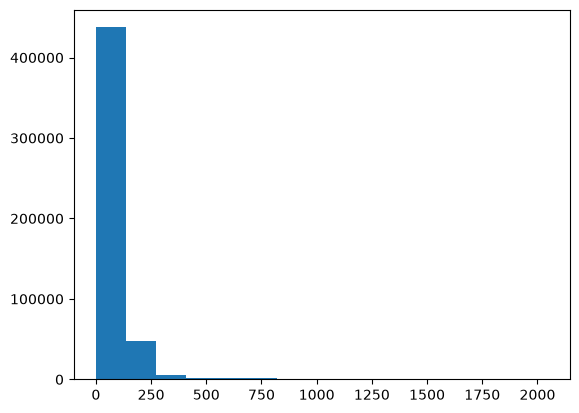

In [16]:
plt.hist(df["open"],bins = 15)

(array([4.37918e+05, 4.72130e+04, 5.81500e+03, 1.91800e+03, 1.47100e+03,
        1.41300e+03, 3.89000e+02, 3.27000e+02, 3.27000e+02, 3.02000e+02,
        1.01000e+02, 5.40000e+01, 7.40000e+01, 1.08000e+02, 3.40000e+01]),
 array([1.69000000e+00, 1.39443333e+02, 2.77196667e+02, 4.14950000e+02,
        5.52703333e+02, 6.90456667e+02, 8.28210000e+02, 9.65963333e+02,
        1.10371667e+03, 1.24147000e+03, 1.37922333e+03, 1.51697667e+03,
        1.65473000e+03, 1.79248333e+03, 1.93023667e+03, 2.06799000e+03]),
 <BarContainer object of 15 artists>)

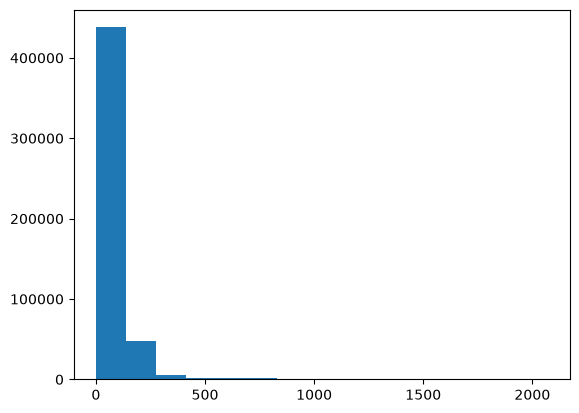

In [17]:
plt.hist(df["high"],bins = 15)

(array([4.37975e+05, 4.72290e+04, 5.79600e+03, 1.89600e+03, 1.44100e+03,
        1.39600e+03, 3.93000e+02, 3.48000e+02, 3.35000e+02, 2.86000e+02,
        9.90000e+01, 5.00000e+01, 6.90000e+01, 1.12000e+02, 3.90000e+01]),
 array([1.500000e+00, 1.370740e+02, 2.726480e+02, 4.082220e+02,
        5.437960e+02, 6.793700e+02, 8.149440e+02, 9.505180e+02,
        1.086092e+03, 1.221666e+03, 1.357240e+03, 1.492814e+03,
        1.628388e+03, 1.763962e+03, 1.899536e+03, 2.035110e+03]),
 <BarContainer object of 15 artists>)

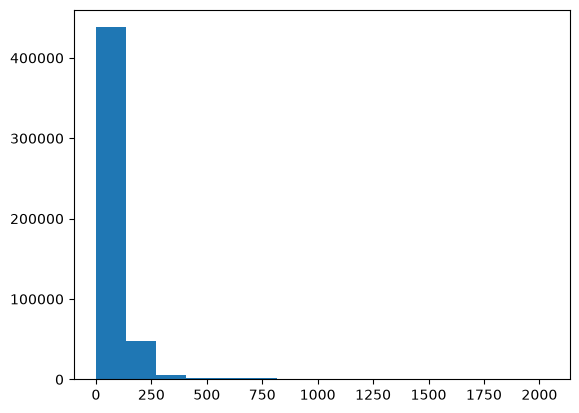

In [18]:
plt.hist(df["low"],bins = 15)

(array([4.37764e+05, 4.73760e+04, 5.83200e+03, 1.90900e+03, 1.46400e+03,
        1.39900e+03, 3.85000e+02, 3.44000e+02, 3.32000e+02, 2.97000e+02,
        9.90000e+01, 5.20000e+01, 7.40000e+01, 1.06000e+02, 3.90000e+01]),
 array([1.590000e+00, 1.380840e+02, 2.745780e+02, 4.110720e+02,
        5.475660e+02, 6.840600e+02, 8.205540e+02, 9.570480e+02,
        1.093542e+03, 1.230036e+03, 1.366530e+03, 1.503024e+03,
        1.639518e+03, 1.776012e+03, 1.912506e+03, 2.049000e+03]),
 <BarContainer object of 15 artists>)

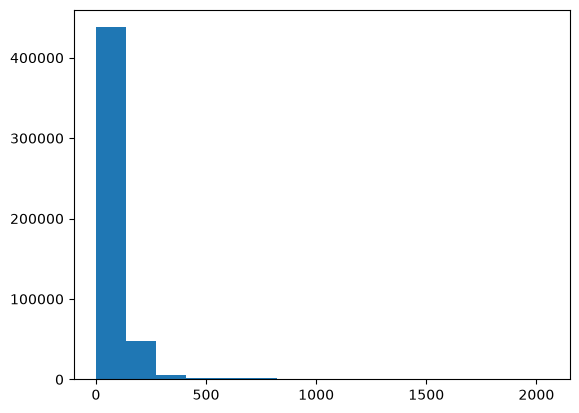

In [19]:
plt.hist(df["close"],bins = 15)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11020\2521196816.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["open"])


<Axes: xlabel='open', ylabel='Density'>

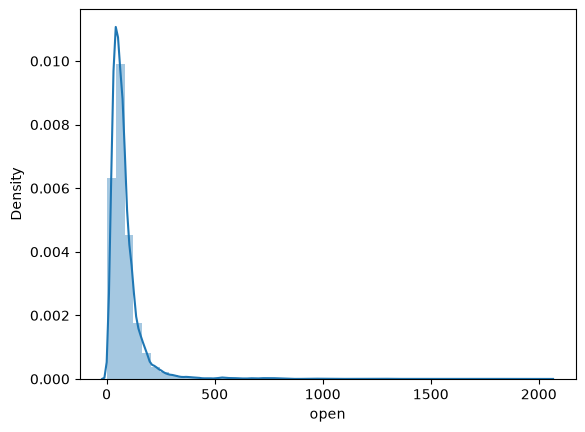

In [20]:
sns.distplot(df["open"])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11020\2270543664.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["high"])


<Axes: xlabel='high', ylabel='Density'>

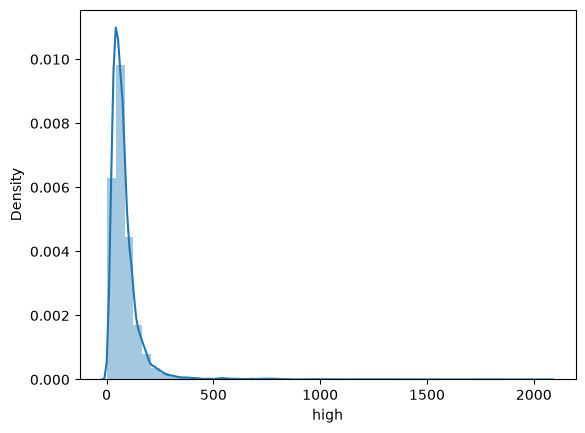

In [21]:
sns.distplot(df["high"])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11020\3340644563.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["low"])


<Axes: xlabel='low', ylabel='Density'>

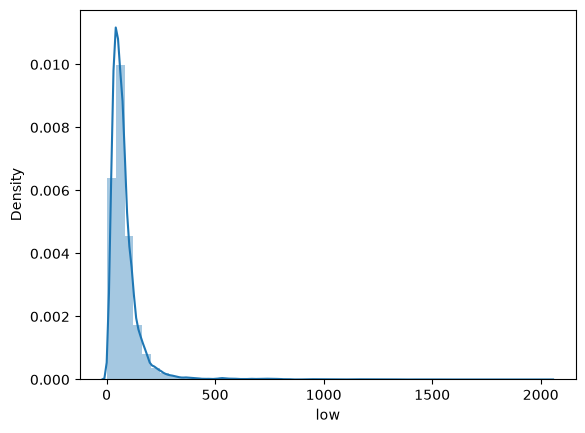

In [22]:
sns.distplot(df["low"])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11020\4034705410.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["close"])


<Axes: xlabel='close', ylabel='Density'>

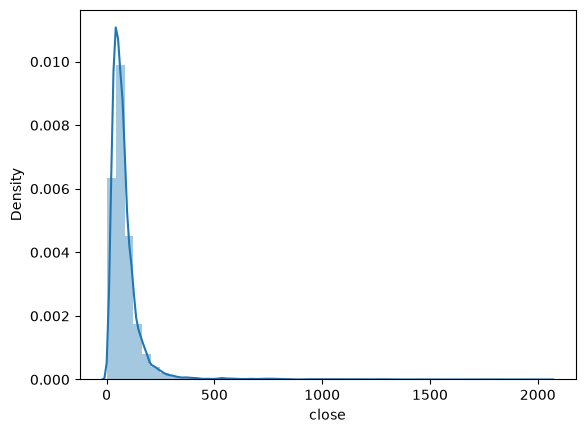

In [23]:
sns.distplot(df["close"])

In [24]:
df["open"]= df["open"].fillna(df["open"].mean())

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11020\2521196816.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["open"])


<Axes: xlabel='open', ylabel='Density'>

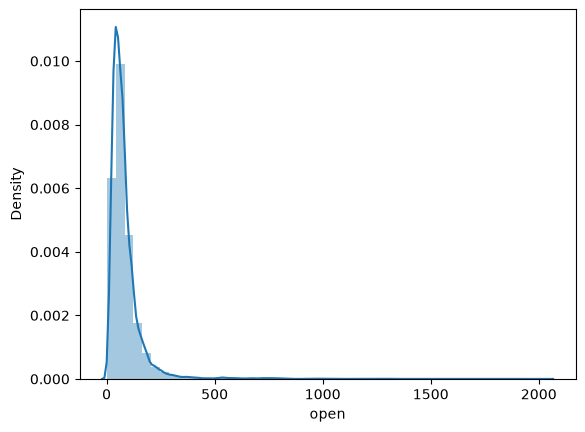

In [25]:
sns.distplot(df["open"])

In [26]:
df["high"]= df["high"].fillna(df["high"].mean())

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11020\2270543664.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["high"])


<Axes: xlabel='high', ylabel='Density'>

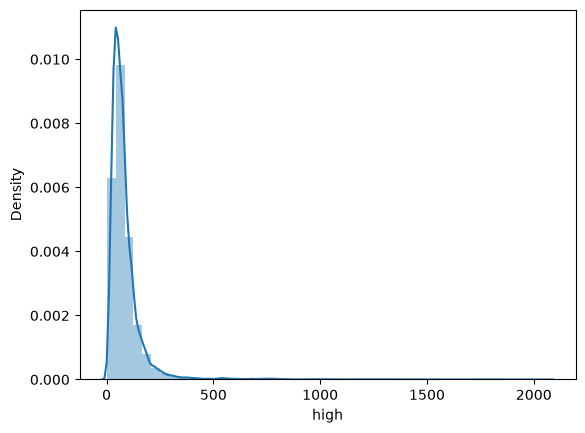

In [27]:
sns.distplot(df["high"])

In [28]:
df["low"]= df["low"].fillna(df["low"].mean())

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11020\3340644563.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["low"])


<Axes: xlabel='low', ylabel='Density'>

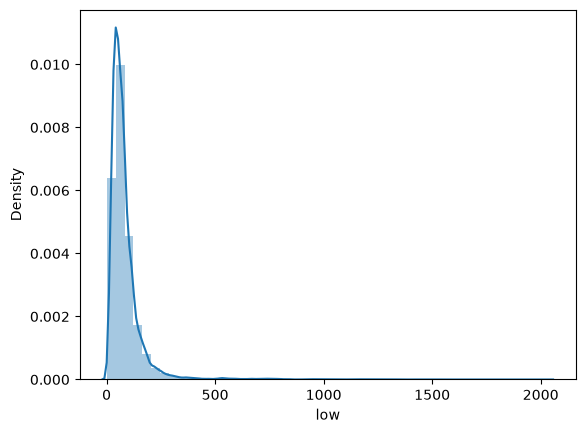

In [29]:
sns.distplot(df["low"])

In [30]:
df.isnull().any()

open      False
high      False
low       False
close     False
volume    False
dtype: bool

In [31]:
df.describe(include = "all")

,open,high,low,close,volume
count,497472.000000,497472.000000,497472.000000,497472.000000,4.974720e+05
mean,86.352275,87.132562,85.552467,86.369082,4.253611e+06
std,101.470106,102.311239,100.570148,101.472407,8.232139e+06
min,1.620000,1.690000,1.500000,1.590000,0.000000e+00
25%,41.690000,42.090000,41.280000,41.703750,1.080166e+06
50%,64.970000,65.560000,64.360000,64.980000,2.084896e+06
75%,98.410000,99.230000,97.580000,98.420000,4.271928e+06
max,2044.000000,2067.990000,2035.110000,2049.000000,6.182376e+08


<Axes: ylabel='open'>

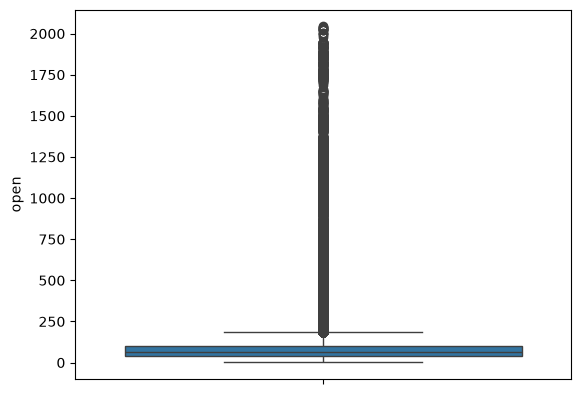

In [32]:
sns.boxplot(df["open"])

<Axes: ylabel='high'>

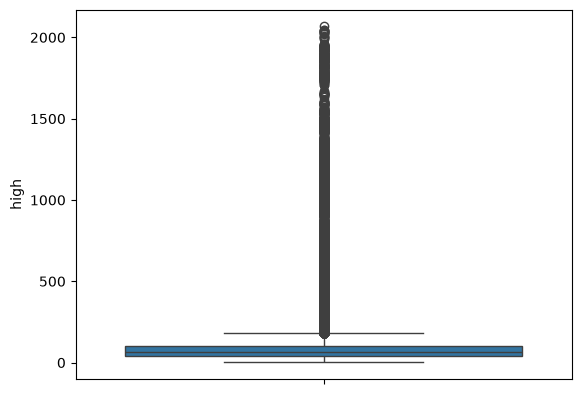

In [33]:
sns.boxplot(df["high"])

<Axes: ylabel='low'>

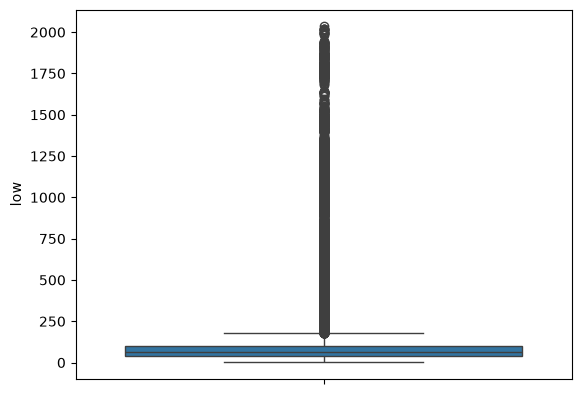

In [34]:
sns.boxplot(df["low"])

<Axes: ylabel='close'>

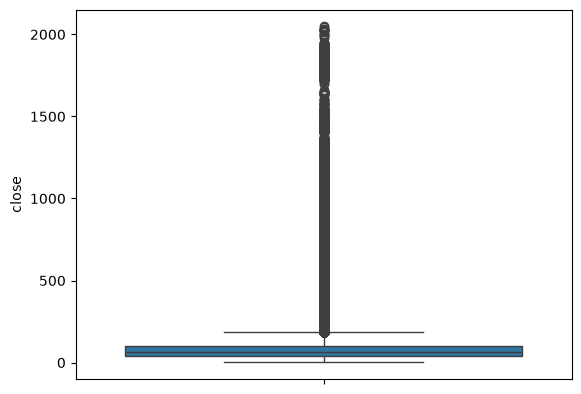

In [35]:
sns.boxplot(df["close"])

<Axes: xlabel='open', ylabel='volume'>

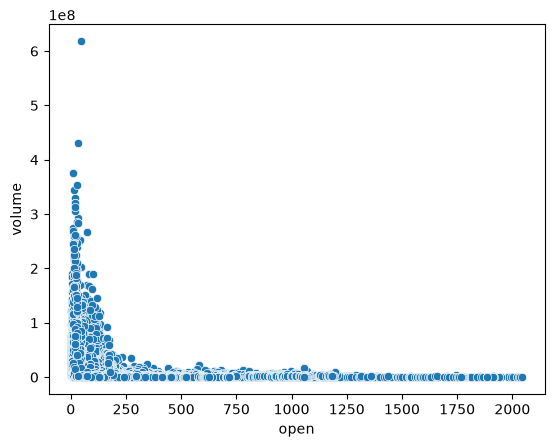

In [36]:
sns.scatterplot(x=df["open"],y=df["volume"])

<Axes: xlabel='high', ylabel='volume'>

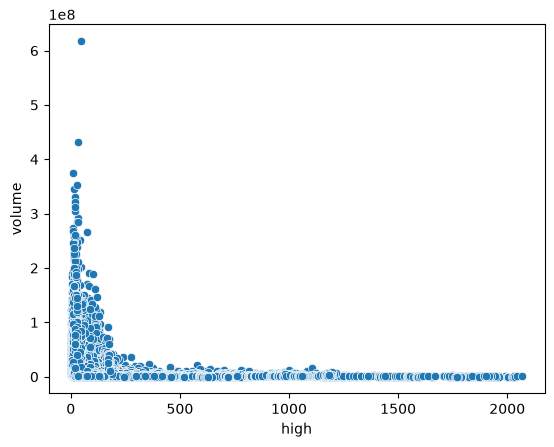

In [37]:
sns.scatterplot(x=df["high"],y=df["volume"])

<Axes: xlabel='low', ylabel='volume'>

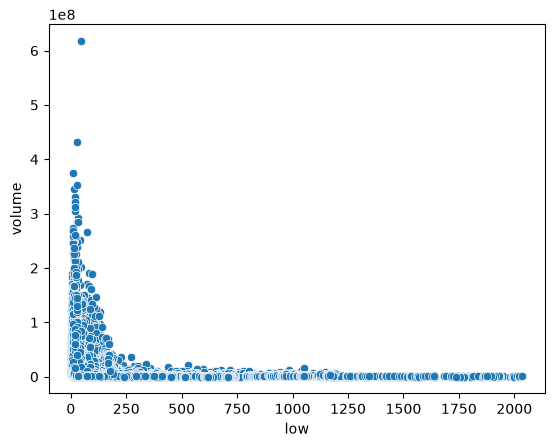

In [38]:
sns.scatterplot(x=df["low"],y=df["volume"])

<Axes: xlabel='close', ylabel='volume'>

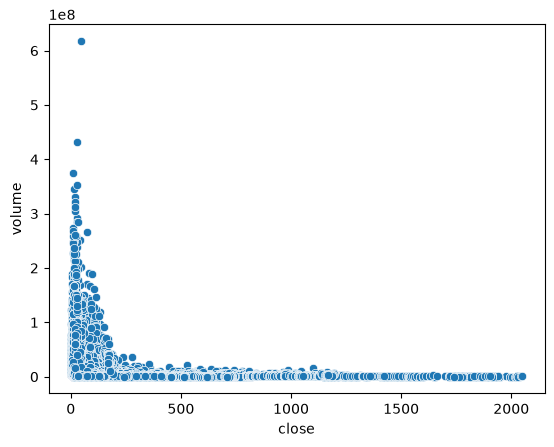

In [39]:
sns.scatterplot(x=df["close"],y=df["volume"])


<Axes: >

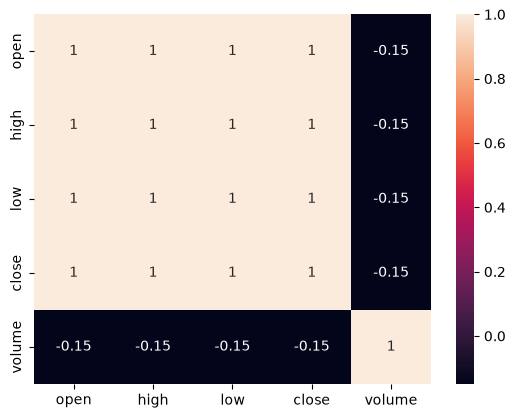

In [40]:
sns.heatmap(df.corr(),annot=True)

In [41]:
df.corr()

,open,high,low,close,volume
open,1.000000,0.999941,0.999927,0.999856,-0.148724
high,0.999941,1.000000,0.999905,0.999918,-0.148344
low,0.999927,0.999905,1.000000,0.999922,-0.149284
close,0.999856,0.999918,0.999922,1.000000,-0.148839
volume,-0.148724,-0.148344,-0.149284,-0.148839,1.000000


In [42]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 497472 entries, 2014-01-02 to 2017-12-29
Data columns (total 5 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   open    497472 non-null  float64
 1   high    497472 non-null  float64
 2   low     497472 non-null  float64
 3   close   497472 non-null  float64
 4   volume  497472 non-null  int64  
dtypes: float64(4), int64(1)
memory usage: 22.8 MB


In [43]:
df.head()

,open,high,low,close,volume
date,,,,,
2014-01-02,25.07,25.82,25.060,25.36,8998943
2014-01-02,15.92,15.98,15.720,15.86,6502296
2014-01-02,53.29,53.38,52.510,52.73,1611326
2014-01-02,61.76,61.95,60.665,60.89,1011050
2014-01-02,41.01,41.01,40.415,40.42,2427140


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11020\107776459.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df)


<Axes: ylabel='Density'>

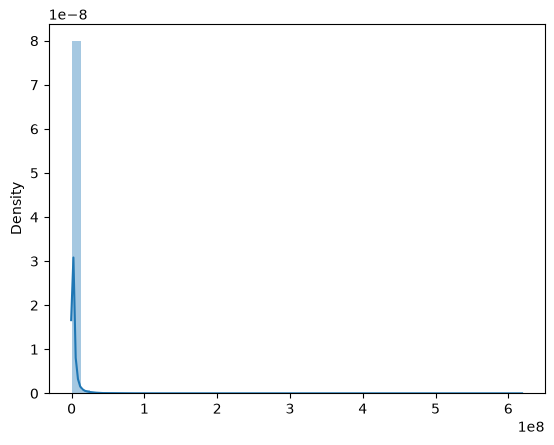

In [44]:
sns.distplot(df)

In [45]:
x=df.drop("volume",axis=1)
y=df["volume"]

In [46]:
x.head()

,open,high,low,close
date,,,,
2014-01-02,25.07,25.82,25.060,25.36
2014-01-02,15.92,15.98,15.720,15.86
2014-01-02,53.29,53.38,52.510,52.73
2014-01-02,61.76,61.95,60.665,60.89
2014-01-02,41.01,41.01,40.415,40.42


In [47]:
y.head()

date
2014-01-02    8998943
2014-01-02    6502296
2014-01-02    1611326
2014-01-02    1011050
2014-01-02    2427140
Name: volume, dtype: int64

In [48]:
xtrain,xtest,ytrain,ytest =  train_test_split(x,y, train_size=0.70,random_state=23)

In [49]:
xtrain.head()

,open,high,low,close
date,,,,
2015-05-14,58.83,58.968,58.49,58.74
2016-08-19,39.33,39.590,38.65,38.84
2014-10-02,53.64,54.540,53.43,54.34
2016-08-16,66.36,66.440,65.68,65.68
2017-02-16,143.34,143.785,141.66,143.24


In [57]:
p, d, q = 2, 1, 2 


arima_model = ARIMA(ytrain, order=(p, d, q)) 
arima_fitted = arima_model.fit()

C:\Users\LENOVO\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\LENOVO\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it is not monotonic and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\LENOVO\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\LENOVO\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it is 

In [59]:
print(arima_fitted.summary())

                               SARIMAX Results                                
Dep. Variable:                 volume   No. Observations:               348230
Model:                 ARIMA(2, 1, 2)   Log Likelihood            -6041568.547
Date:                Mon, 28 Sep 2026   AIC                       12083147.095
Time:                        20:28:00   BIC                       12083200.898
Sample:                             0   HQIC                      12083162.558
                             - 348230                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9892      0.015    -65.354      0.000      -1.019      -0.959
ar.L2          0.0024      0.002      1.243      0.214      -0.001       0.006
ma.L1         -0.0082      0.015     -0.544      0.5